# Grayscale Intensity Transformations, Histogram Enhancement and Thresholding

**How to use:** put your own JPG/PNG (at least 300 × 300 px) next to this notebook and change `IMAGE_PATH` in the first code cell. Then use *Run All*.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "input_image.png"   

# ---------- helper functions ----------
def to_uint8(x):
    """Clip to 0-255 first, then convert to uint8 (astype truncates the fraction)."""
    return np.clip(x, 0, 255).astype(np.uint8)

def show_images(images, titles, cols=None, size=4):
    """Show grayscale images with fixed limits 0-255."""
    n = len(images)
    cols = cols or n
    rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def plot_hist(ax, img, title):
    """256-bin histogram over 0-256."""
    ax.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
    ax.set_xlim(0, 256)
    ax.set_title(title)
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Pixel count")

def show_rows(**rows):
    """Print labelled rows of a dry-run table."""
    for name, vals in rows.items():
        print(f"{name:<14}", np.asarray(vals).tolist())

def round_half_up(x):
    return np.floor(np.asarray(x, dtype=np.float64) + 0.5).astype(int)

def stats(name, img):
    print(f"{name:<28} mean={img.mean():7.2f}  std={img.std():6.2f}  "
          f"pixels==255: {(img == 255).sum():>7}  pixels==0: {(img == 0).sum():>7}")

## Load and validate the image

Shape: (512, 512)
dtype: uint8
Min  : 0
Max  : 255


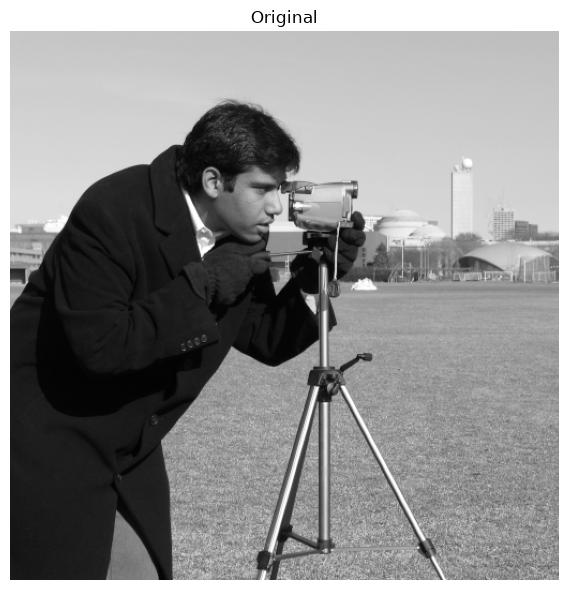

In [2]:
loaded = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)      # 8-bit grayscale
assert loaded is not None, f"Could not read '{IMAGE_PATH}'"
assert loaded.ndim == 2 and loaded.dtype == np.uint8, "Image must be 8-bit grayscale"
h, w = loaded.shape
assert h >= 300 and w >= 300, "Image must be at least 300 x 300 pixels"

original = loaded.copy()
original.setflags(write=False)          # keep the original unchanged

print("Shape:", original.shape)
print("dtype:", original.dtype)
print("Min  :", original.min())
print("Max  :", original.max())
show_images([original], ["Original"], size=6)

## 1. Brightness adjustment  (s = r + β, β = ±40)
### Dry run

In [3]:
p = np.array([30, 80, 128, 180, 240], dtype=np.uint8)
print("Pixels r:", p.tolist())

for beta, expected in [(40, [70, 120, 168, 220, 255]), (-40, [0, 40, 88, 140, 200])]:
    raw = p.astype(np.int16) + beta            # wider type: no uint8 overflow
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    print(f"\nβ = {beta:+d}")
    show_rows(raw=raw, clipped=clipped, final_uint8=final)
    assert final.tolist() == expected

Pixels r: [30, 80, 128, 180, 240]

β = +40
raw            [70, 120, 168, 220, 280]
clipped        [70, 120, 168, 220, 255]
final_uint8    [70, 120, 168, 220, 255]

β = -40
raw            [-10, 40, 88, 140, 200]
clipped        [0, 40, 88, 140, 200]
final_uint8    [0, 40, 88, 140, 200]


**Lost detail:** with β = +40, 240 → 280 is clipped to 255 (saturated), so any brighter pixel also becomes 255 and bright detail is lost. With β = −40, 30 → −10 is clipped to 0, so dark detail is lost. Values that are clipped can never be recovered.

Loop result matches NumPy (+40): True


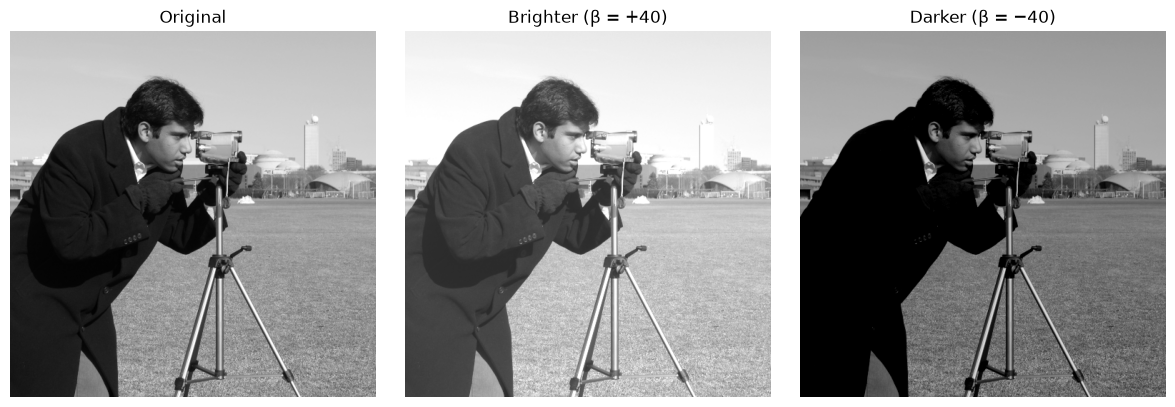

Original                     mean= 129.06  std= 73.64  pixels==255:     271  pixels==0:       1
Brighter +40                 mean= 168.65  std= 73.10  pixels==255:   10393  pixels==0:       0
Darker -40                   mean=  93.68  std= 66.89  pixels==255:       0  pixels==0:   69932


In [4]:
orig16 = original.astype(np.int16)
brighter = to_uint8(orig16 + 40)
darker   = to_uint8(orig16 - 40)

# nested-loop version of +40
rows = original.tolist()
loop_result = np.array(
    [[min(255, rows[i][j] + 40) for j in range(w)] for i in range(h)],
    dtype=np.uint8)
print("Loop result matches NumPy (+40):", np.array_equal(loop_result, brighter))

show_images([original, brighter, darker],
            ["Original", "Brighter (β = +40)", "Darker (β = −40)"])
stats("Original", original); stats("Brighter +40", brighter); stats("Darker -40", darker)

## 2. Linear contrast from zero  (s = 1.5 r)
### Dry run

In [5]:
raw = 1.5 * p.astype(np.float64)
clipped = np.clip(raw, 0, 255)
final = clipped.astype(np.uint8)                  # truncate
show_rows(r=p, raw_1p5r=raw, clipped=clipped, final_uint8=final)
print("Saturated pixels (r):", p[raw >= 255].tolist())
assert final.tolist() == [45, 120, 192, 255, 255]

r              [30, 80, 128, 180, 240]
raw_1p5r       [45.0, 120.0, 192.0, 270.0, 360.0]
clipped        [45.0, 120.0, 192.0, 255.0, 255.0]
final_uint8    [45, 120, 192, 255, 255]
Saturated pixels (r): [180, 240]


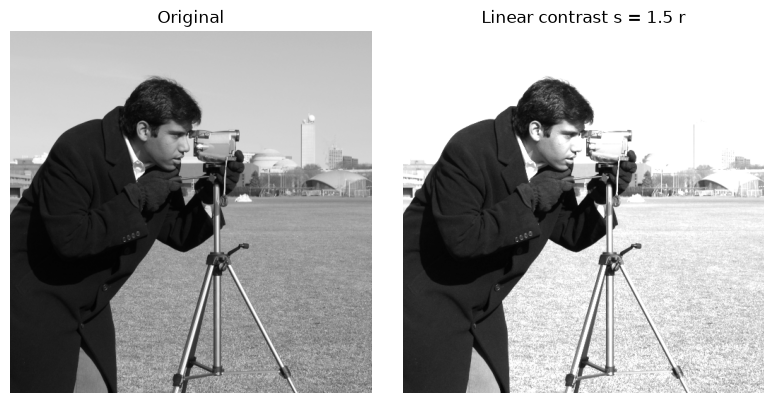

Original                     mean= 129.06  std= 73.64  pixels==255:     271  pixels==0:       1
s = 1.5 r                    mean= 176.31  std= 93.99  pixels==255:   91311  pixels==0:       1


In [6]:
lin0 = to_uint8(1.5 * original.astype(np.float64))
show_images([original, lin0], ["Original", "Linear contrast s = 1.5 r"])
stats("Original", original); stats("s = 1.5 r", lin0)

**Observation:** multiplying by 1.5 about zero makes the image brighter overall (the mean rises) and every pixel with r ≥ 170 saturates at 255, so highlights are clipped and their detail is lost.

## 3. Contrast centered at 128  (s = (r − 128)α + 128)
### Dry run

In [7]:
expected = {1.5: [0, 56, 128, 206, 255], 0.5: [79, 104, 128, 154, 184]}
for a in (1.5, 0.5):
    diff = p.astype(np.float64) - 128
    scaled = diff * a
    raw = scaled + 128
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    print(f"\nα = {a}")
    show_rows(r=p, r_minus_128=diff, times_alpha=scaled, plus_128=raw,
              clipped=clipped, final_uint8=final)
    assert final.tolist() == expected[a]


α = 1.5
r              [30, 80, 128, 180, 240]
r_minus_128    [-98.0, -48.0, 0.0, 52.0, 112.0]
times_alpha    [-147.0, -72.0, 0.0, 78.0, 168.0]
plus_128       [-19.0, 56.0, 128.0, 206.0, 296.0]
clipped        [0.0, 56.0, 128.0, 206.0, 255.0]
final_uint8    [0, 56, 128, 206, 255]

α = 0.5
r              [30, 80, 128, 180, 240]
r_minus_128    [-98.0, -48.0, 0.0, 52.0, 112.0]
times_alpha    [-49.0, -24.0, 0.0, 26.0, 56.0]
plus_128       [79.0, 104.0, 128.0, 154.0, 184.0]
clipped        [79.0, 104.0, 128.0, 154.0, 184.0]
final_uint8    [79, 104, 128, 154, 184]


**At r = 128:** (128 − 128)·α + 128 = 128 for every α, so the centre value is a fixed point. Values above 128 move away from (α > 1) or towards (α < 1) 128, and the same happens below it, so contrast changes without a large shift in overall brightness.

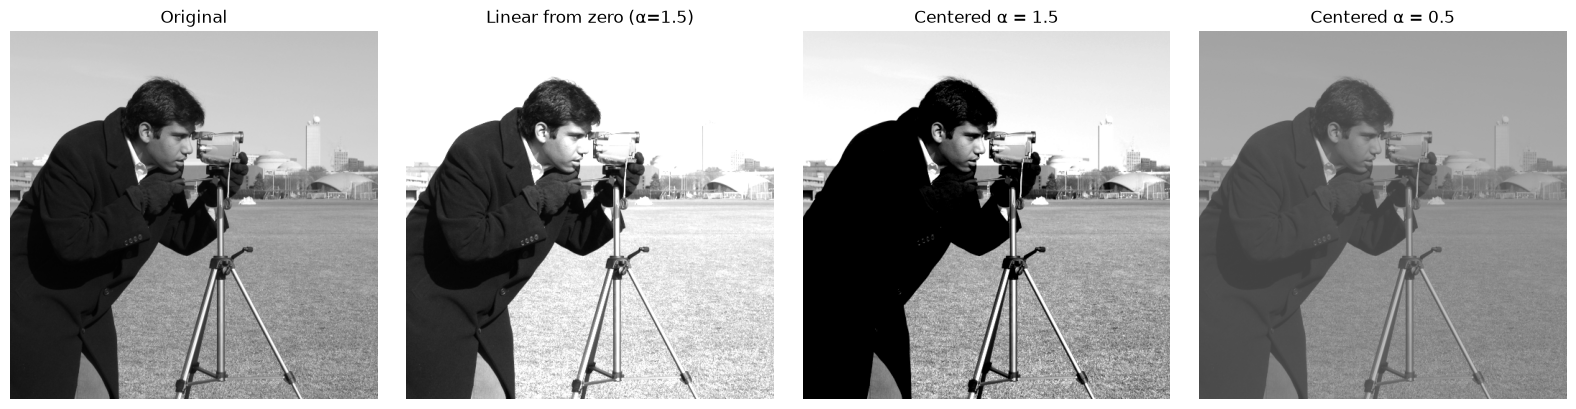

Original                     mean= 129.06  std= 73.64  pixels==255:     271  pixels==0:       1
Linear 1.5 r                 mean= 176.31  std= 93.99  pixels==255:   91311  pixels==0:       1
Centered 1.5                 mean= 136.65  std= 97.70  pixels==255:   15336  pixels==0:   71306
Centered 0.5                 mean= 128.28  std= 36.82  pixels==255:       0  pixels==0:       0


In [8]:
orig_f = original.astype(np.float64)
cen_15 = to_uint8((orig_f - 128) * 1.5 + 128)
cen_05 = to_uint8((orig_f - 128) * 0.5 + 128)

show_images([original, lin0, cen_15, cen_05],
            ["Original", "Linear from zero (α=1.5)", "Centered α = 1.5", "Centered α = 0.5"], cols=4)
stats("Original", original); stats("Linear 1.5 r", lin0)
stats("Centered 1.5", cen_15); stats("Centered 0.5", cen_05)

**Comparison:** linear contrast from zero brightens the image and clips only highlights. Centered α = 1.5 keeps the mean brightness near the original but clips both shadows and highlights. Centered α = 0.5 compresses all values towards 128 (flatter, lower contrast, nothing clipped).

## 4. Image negative  (s = 255 − r)
### Dry run

In [9]:
neg = 255 - p.astype(np.int16)
neg_neg = 255 - neg
show_rows(r=p, negative=neg, negative_again=neg_neg)
assert neg.tolist() == [225, 175, 127, 75, 15]
assert np.array_equal(neg_neg, p), "double negative must equal original"
print("Double negative equals original: True")

r              [30, 80, 128, 180, 240]
negative       [225, 175, 127, 75, 15]
negative_again [30, 80, 128, 180, 240]
Double negative equals original: True


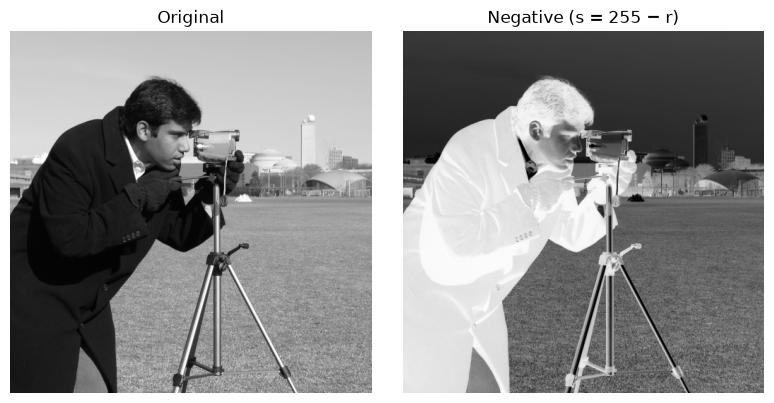

Negative of negative equals original: True


In [10]:
negative = to_uint8(255 - original.astype(np.int16))
show_images([original, negative], ["Original", "Negative (s = 255 − r)"])
print("Negative of negative equals original:",
      np.array_equal(to_uint8(255 - negative.astype(np.int16)), original))

**Useful when:** bright-on-dark fine detail is hard to see, e.g. light-grey lesions or bone details in dark X-ray regions. Inverting makes those details dark on a bright background, where the eye often separates small intensity differences more easily.

## 5. Gamma correction  (s = 255 (r/255)^γ)
### Dry run

In [11]:
g_pix = np.array([0, 64, 128, 192, 255], dtype=np.uint8)
expected = {0.5: [0, 127, 180, 221, 255], 2.0: [0, 16, 64, 144, 255]}
for g in (0.5, 2.0):
    norm = g_pix.astype(np.float64) / 255
    powered = norm ** g
    scaled = 255 * powered                            # full precision
    final = scaled.astype(np.uint8)                   # truncate only at the end
    print(f"\nγ = {g}")
    show_rows(r=g_pix, normalised=np.round(norm, 6), power=np.round(powered, 6),
              scaled=np.round(scaled, 4), truncated=final, rounded=np.rint(scaled).astype(int))
    assert final.tolist() == expected[g]


γ = 0.5
r              [0, 64, 128, 192, 255]
normalised     [0.0, 0.25098, 0.501961, 0.752941, 1.0]
power          [0.0, 0.500979, 0.708492, 0.867722, 1.0]
scaled         [0.0, 127.7498, 180.6654, 221.2691, 255.0]
truncated      [0, 127, 180, 221, 255]
rounded        [0, 128, 181, 221, 255]

γ = 2.0
r              [0, 64, 128, 192, 255]
normalised     [0.0, 0.25098, 0.501961, 0.752941, 1.0]
power          [0.0, 0.062991, 0.251965, 0.56692, 1.0]
scaled         [0.0, 16.0627, 64.251, 144.5647, 255.0]
truncated      [0, 16, 64, 144, 255]
rounded        [0, 16, 64, 145, 255]


**Difference from the rounded slide example:** slides usually round the intermediate values (e.g. r/255 ≈ 0.25, 0.50, 0.75) and round the final result. Here full precision is kept (r/255 = 0.25098, 0.50196 …) and the final value is truncated, so some outputs differ by 1 (e.g. 127.75 → 127 instead of 128). The "rounded" row above shows the round-to-nearest result for comparison.

0 and 255 remain fixed for γ = 0.5 and 2.0: True


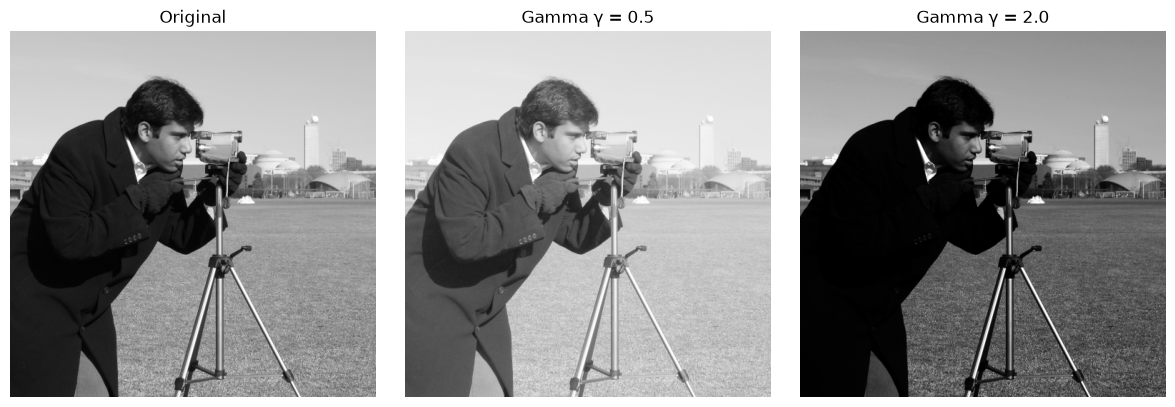

Mean of originally dark pixels (r < 64): original=25.4, γ=0.5 -> 76.9, γ=2.0 -> 2.7


In [27]:
def gamma_correct(img, g):
    return to_uint8(255 * (img.astype(np.float64) / 255) ** g)

gamma_05 = gamma_correct(original, 0.5)
gamma_20 = gamma_correct(original, 2.0)

# 0 and 255 stay fixed
lut_check = gamma_correct(np.array([0, 255], dtype=np.uint8), 0.5), gamma_correct(np.array([0, 255], dtype=np.uint8), 2.0)
assert all(l.tolist() == [0, 255] for l in lut_check)
print("0 and 255 remain fixed for γ = 0.5 and 2.0: True")

show_images([original, gamma_05, gamma_20],
            ["Original", "Gamma γ = 0.5", "Gamma γ = 2.0"])


dark = original < 64
print(f"Mean of originally dark pixels (r < 64): original={original[dark].mean():.1f}, "
      f"γ=0.5 -> {gamma_05[dark].mean():.1f}, γ=2.0 -> {gamma_20[dark].mean():.1f}")

## Plot the gamma transfer curves

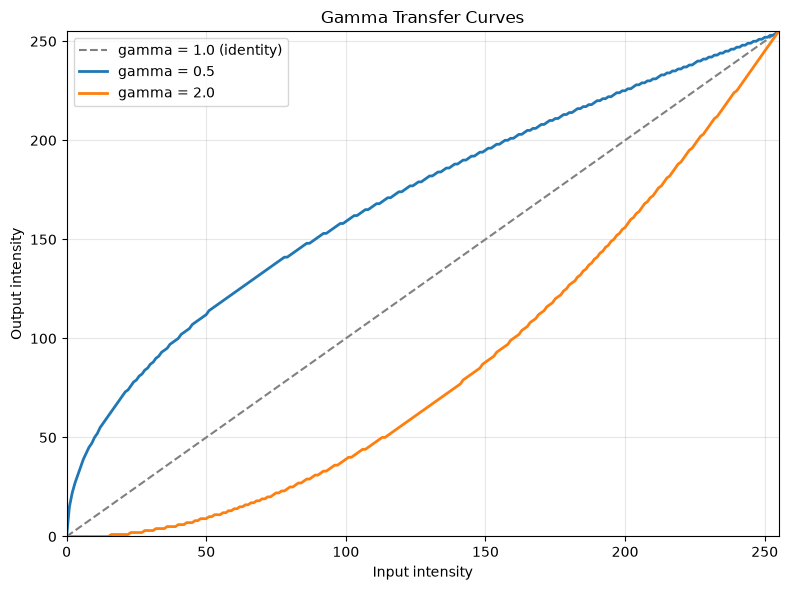

In [29]:

input_levels = np.arange(256, dtype=np.uint8)
gamma_05_curve = gamma_correct(input_levels, 0.5)
gamma_20_curve = gamma_correct(input_levels, 2.0)

plt.figure(figsize=(8, 6))
plt.plot(input_levels, input_levels, linestyle="--", color="gray", label="gamma = 1.0 (identity)")
plt.plot(input_levels, gamma_05_curve, linewidth=2, label="gamma = 0.5")
plt.plot(input_levels, gamma_20_curve, linewidth=2, label="gamma = 2.0")
plt.title("Gamma Transfer Curves")
plt.xlabel("Input intensity")
plt.ylabel("Output intensity")
plt.xlim(0, 255)
plt.ylim(0, 255)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Effect on dark regions:** γ = 0.5 lifts dark regions strongly (image brighter, shadow detail revealed), whereas γ = 2.0 pushes dark regions even darker (image darker, shadow detail suppressed, highlights preserved).

## 6. Grayscale histogram
### Dry run

In [13]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
counts = np.bincount(A.ravel(), minlength=256)
nz = np.nonzero(counts)[0]
total = A.size
print("Intensity :", nz.tolist())
print("Frequency :", counts[nz].tolist())
print("Probability:", [f"{c}/{total} = {c/total:.3f}" for c in counts[nz]])
print("Total pixels:", total, "| sum of frequencies:", counts.sum())
assert counts[nz].tolist() == [1, 2, 2, 1, 1, 1] and total == 8

Intensity : [0, 50, 100, 150, 200, 255]
Frequency : [1, 2, 2, 1, 1, 1]
Probability: ['1/8 = 0.125', '2/8 = 0.250', '2/8 = 0.250', '1/8 = 0.125', '1/8 = 0.125', '1/8 = 0.125']
Total pixels: 8 | sum of frequencies: 8


**Why positions are not shown:** a histogram only counts how many pixels have each intensity. Rearranging the pixels (e.g. shuffling A) gives exactly the same histogram, so spatial information is discarded.

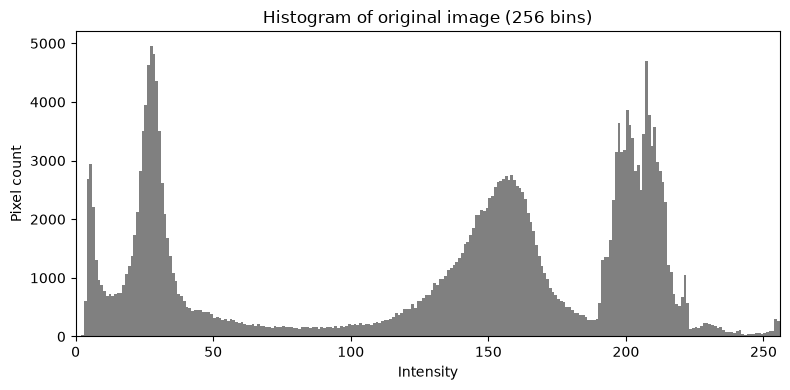

1) Pixel values span 0–255 with a mean of 129.1 and a standard deviation of 73.6.
2) 29.6% of pixels are dark (<64) and 30.1% are bright (≥192), so the image is mid-toned with a wide spread of intensities.


In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_hist(ax, original, "Histogram of original image (256 bins)")
plt.tight_layout(); plt.show()

m = original.mean()
dark_pct = 100 * (original < 64).mean()
bright_pct = 100 * (original >= 192).mean()
print(f"1) Pixel values span {original.min()}–{original.max()} with a mean of {m:.1f} and a standard deviation of {original.std():.1f}.")
print(f"2) {dark_pct:.1f}% of pixels are dark (<64) and {bright_pct:.1f}% are bright (≥192), so the image is "
      f"{'dark-leaning' if m < 100 else 'bright-leaning' if m > 156 else 'mid-toned'} "
      f"with {'a wide' if original.std() > 60 else 'a fairly narrow'} spread of intensities.")

## 7. Global histogram equalization
### Dry run

In [15]:
q = np.array([50, 50, 100, 150], dtype=np.uint8)
vals, freq = np.unique(q, return_counts=True)
cum = np.cumsum(freq)
cdf = cum / q.size
show_rows(intensity=vals, frequency=freq, cumulative=cum, CDF=cdf)

map1 = round_half_up(255 * cdf)
cdf_min = cdf[cdf > 0].min()
map2 = round_half_up(255 * (cdf - cdf_min) / (1 - cdf_min))
print("\nCDFmin =", cdf_min)
show_rows(map_255xCDF=map1, map_with_CDFmin=map2)

idx = np.searchsorted(vals, q)
out1, out2 = map1[idx], map2[idx]
print("\nOutput (255 × CDF)               :", out1.tolist())
print("Output (255 × (CDF−CDFmin)/(1−CDFmin)):", out2.tolist())

cv_out = cv2.equalizeHist(q.reshape(1, -1)).ravel()
print("OpenCV equalizeHist               :", cv_out.tolist())
assert out1.tolist() == [128, 128, 191, 255]
assert out2.tolist() == [0, 0, 128, 255]
assert np.array_equal(out2, cv_out)
print("Second formula matches OpenCV: True")

intensity      [50, 100, 150]
frequency      [2, 1, 1]
cumulative     [2, 3, 4]
CDF            [0.5, 0.75, 1.0]

CDFmin = 0.5
map_255xCDF    [128, 191, 255]
map_with_CDFmin [0, 128, 255]

Output (255 × CDF)               : [128, 128, 191, 255]
Output (255 × (CDF−CDFmin)/(1−CDFmin)): [0, 0, 128, 255]
OpenCV equalizeHist               : [0, 0, 128, 255]
Second formula matches OpenCV: True


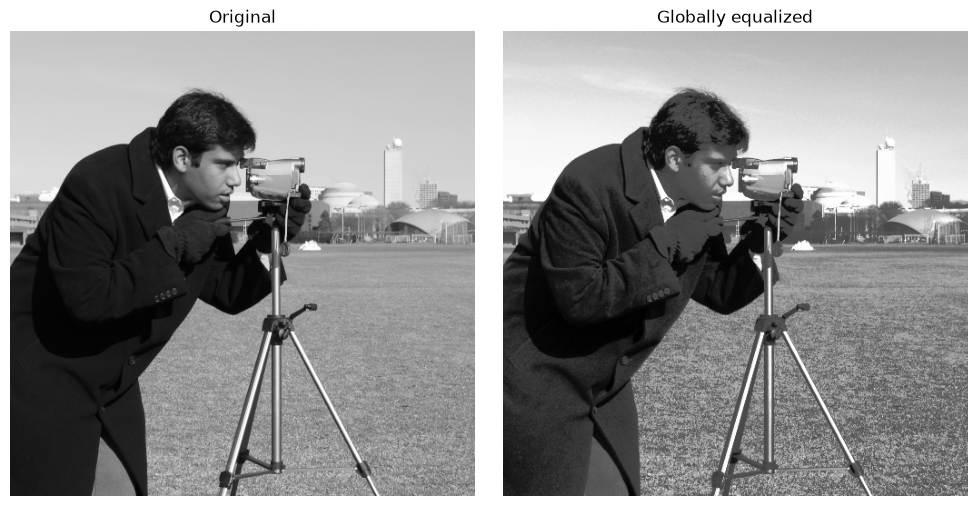

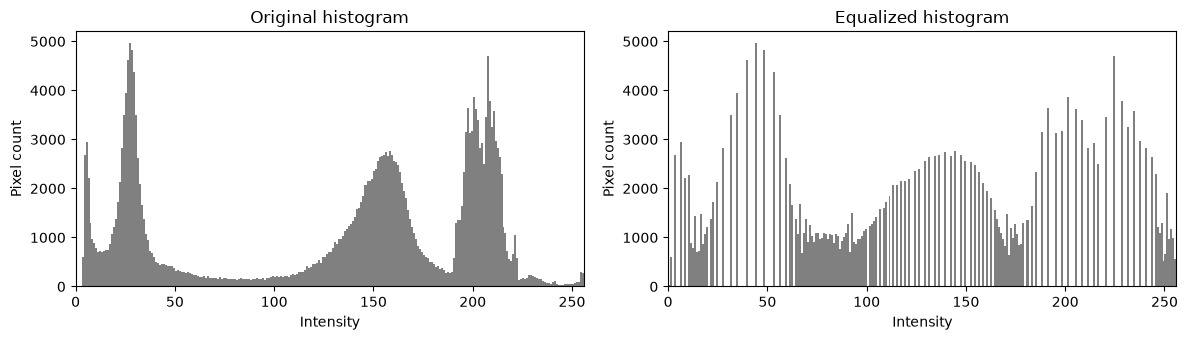

Std (contrast): original=73.64, equalized=73.67
Laplacian variance (noise/detail proxy): original=1133.2, equalized=2753.4


In [16]:
equalized = cv2.equalizeHist(original)

show_images([original, equalized], ["Original", "Globally equalized"], size=5)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_hist(axes[0], original, "Original histogram")
plot_hist(axes[1], equalized, "Equalized histogram")
plt.tight_layout(); plt.show()

lap = lambda im: cv2.Laplacian(im, cv2.CV_64F).var()   # high-frequency / noise proxy
print(f"Std (contrast): original={original.std():.2f}, equalized={equalized.std():.2f}")
print(f"Laplacian variance (noise/detail proxy): original={lap(original):.1f}, equalized={lap(equalized):.1f}")

**Discussion:** equalization spreads intensities over the full 0–255 range, which usually improves visibility of detail in low-contrast areas. However, it is global, so bright/dark regions can be over-enhanced, and it amplifies noise in flat regions (the higher Laplacian variance above reflects stronger fine texture/noise).

## 8. CLAHE  (clipLimit = 2.0, tileGridSize = (8, 8))
### Dry run

In [19]:
hist = np.array([6, 2, 0, 0], dtype=np.float64)
cap = 4
clipped = np.minimum(hist, cap)
excess = (hist - clipped).sum()
redistributed = clipped + excess / hist.size           # fractions allowed

cdf_before = np.cumsum(hist) / hist.sum()
cdf_after = np.cumsum(redistributed) / redistributed.sum()

show_rows(original_hist=hist, clipped=clipped)
print("Excess removed:", excess, "-> added per bin:", excess / hist.size)
show_rows(redistributed=redistributed, CDF_before=cdf_before, CDF_after=cdf_after)
assert redistributed.tolist() == [4.5, 2.5, 0.5, 0.5]
assert np.allclose(cdf_after, [0.5625, 0.875, 0.9375, 1.0])

original_hist  [6.0, 2.0, 0.0, 0.0]
clipped        [4.0, 2.0, 0.0, 0.0]
Excess removed: 2.0 -> added per bin: 0.5
redistributed  [4.5, 2.5, 0.5, 0.5]
CDF_before     [0.75, 1.0, 1.0, 1.0]
CDF_after      [0.5625, 0.875, 0.9375, 1.0]


**Interpolation:** each tile has its own mapping (CDF). Using one tile's mapping for all of its pixels would give visible jumps at tile borders, so CLAHE bilinearly interpolates between the mappings of neighbouring tiles.

**Note:** this is a simplified model (absolute cap, fractional redistribution); OpenCV uses integer redistribution, and its `clipLimit` is a relative factor, not an absolute cap.

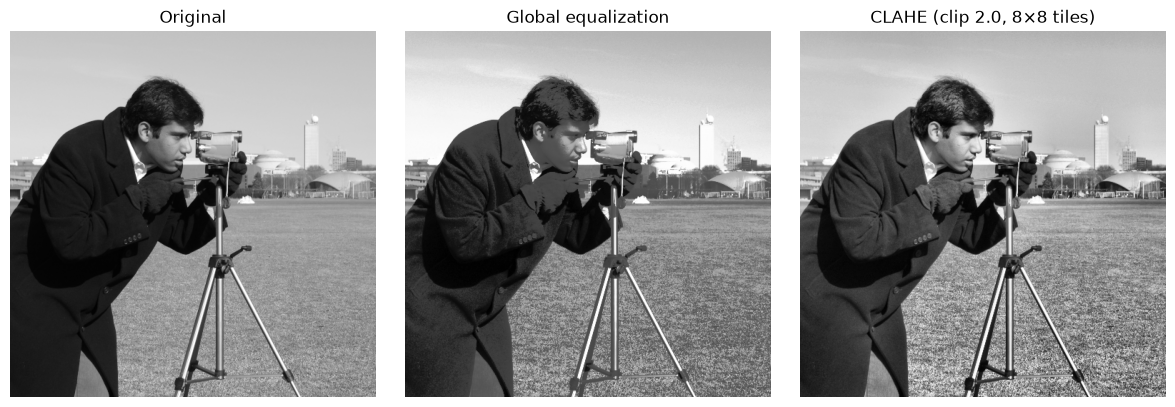

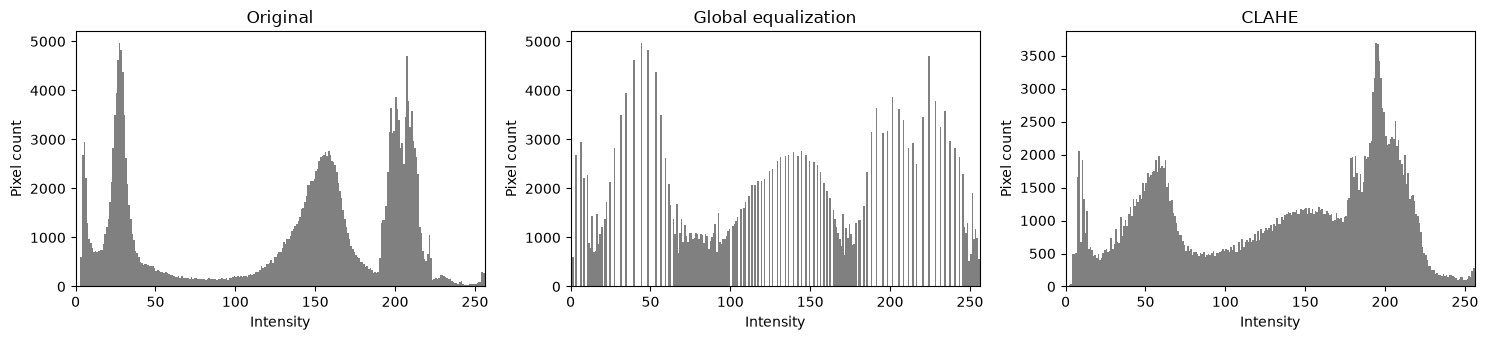

Laplacian variance: global=2753.4, CLAHE=4200.0


In [17]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(original)

show_images([original, equalized, clahe_img],
            ["Original", "Global equalization", "CLAHE (clip 2.0, 8×8 tiles)"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
plot_hist(axes[0], original, "Original")
plot_hist(axes[1], equalized, "Global equalization")
plot_hist(axes[2], clahe_img, "CLAHE")
plt.tight_layout(); plt.show()
print(f"Laplacian variance: global={lap(equalized):.1f}, CLAHE={lap(clahe_img):.1f}")

**Comparison:** global equalization uses one mapping for the whole image, so under uneven lighting a bright area can wash out while a dark area stays dark. CLAHE equalizes each local tile with a limited contrast gain, so local detail appears in both dark and bright regions with less noise amplification.

**Tile grid:** `(8, 8)` means the image is split into 8 × 8 = 64 tiles (8 columns and 8 rows) — it does **not** mean 8 × 8 pixels per tile. Tile size in pixels = image size / 8.

## 9. Fixed binary thresholding  (T = 127)
### Dry run

In [18]:
t_pix = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
expected = {127: [0, 0, 0, 255, 255, 255], 180: [0, 0, 0, 0, 0, 255]}
for T in (127, 180):
    res = np.where(t_pix > T, 255, 0).astype(np.uint8)
    print(f"T = {T}: r > T -> {(t_pix > T).tolist()}")
    show_rows(r=t_pix, output=res)
    print("White pixels:", int((res == 255).sum()), "\n")
    assert res.tolist() == expected[T]

T = 127: r > T -> [False, False, False, True, True, True]
r              [0, 80, 127, 128, 180, 255]
output         [0, 0, 0, 255, 255, 255]
White pixels: 3 

T = 180: r > T -> [False, False, False, False, False, True]
r              [0, 80, 127, 128, 180, 255]
output         [0, 0, 0, 0, 0, 255]
White pixels: 1 



Raising T from 127 to 180 reduces the white count from 3 to 1, because fewer pixels satisfy r > T.

Unique values: [0, 255]


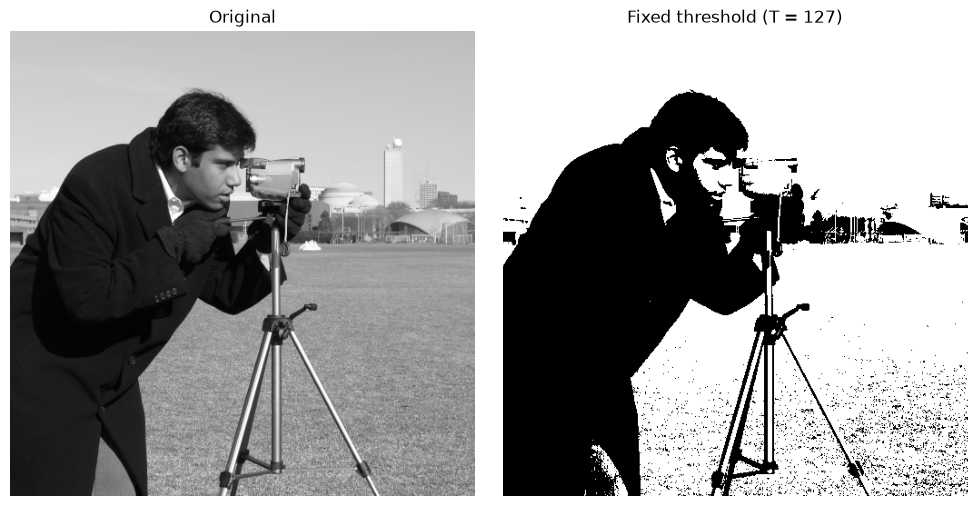

In [20]:
_, fixed = cv2.threshold(original, 127, 255, cv2.THRESH_BINARY)
print("Unique values:", np.unique(fixed).tolist())
show_images([original, fixed], ["Original", "Fixed threshold (T = 127)"], size=5)

## 10. Otsu thresholding
### Dry run

In [21]:
o = np.array([0, 1, 4, 5], dtype=np.uint8)
N = o.size
best_T, best_val = None, -1
print(f"{'T':>2} {'w0':>5} {'w1':>5} {'mu0':>6} {'mu1':>6} {'w0*w1*(mu0-mu1)^2':>20}")
for T in range(5):
    c0, c1 = o[o <= T], o[o > T]
    w0, w1 = len(c0) / N, len(c1) / N
    mu0, mu1 = c0.mean(), c1.mean()
    var_b = w0 * w1 * (mu0 - mu1) ** 2
    print(f"{T:>2} {w0:>5.2f} {w1:>5.2f} {mu0:>6.3f} {mu1:>6.3f} {var_b:>20.4f}")
    if var_b > best_val + 1e-12:          # strict '>' keeps the smallest T among ties
        best_T, best_val = T, var_b

pred_mask = np.where(o > best_T, 255, 0).astype(np.uint8)
cv_T, cv_mask = cv2.threshold(o.reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("\nBest T (smallest among ties):", best_T, "| max between-class variance:", round(best_val, 4))
print("Predicted mask:", pred_mask.tolist())
print("OpenCV mask   :", cv_mask.ravel().tolist(), "| OpenCV threshold:", cv_T)
assert best_T == 1 and pred_mask.tolist() == [0, 0, 255, 255]
assert np.array_equal(pred_mask, cv_mask.ravel())
print("Predicted mask matches OpenCV: True")

 T    w0    w1    mu0    mu1    w0*w1*(mu0-mu1)^2
 0  0.25  0.75  0.000  3.333               2.0833
 1  0.50  0.50  0.500  4.500               4.0000
 2  0.50  0.50  0.500  4.500               4.0000
 3  0.50  0.50  0.500  4.500               4.0000
 4  0.75  0.25  1.667  5.000               2.0833

Best T (smallest among ties): 1 | max between-class variance: 4.0
Predicted mask: [0, 0, 255, 255]
OpenCV mask   : [0, 0, 255, 255] | OpenCV threshold: 1.0
Predicted mask matches OpenCV: True


T = 1, 2 and 3 give the same split ({0,1} | {4,5}) and the same maximum (4.0), so the smallest, T = 1, is chosen. Any T in 1–3 yields the identical mask, so the mask matches OpenCV even if OpenCV reports a different tied threshold value.

Otsu threshold returned: 102.0
Pixels where fixed (127) and Otsu masks differ: 9425 (3.60%)
White pixels: fixed=168559, Otsu=177984


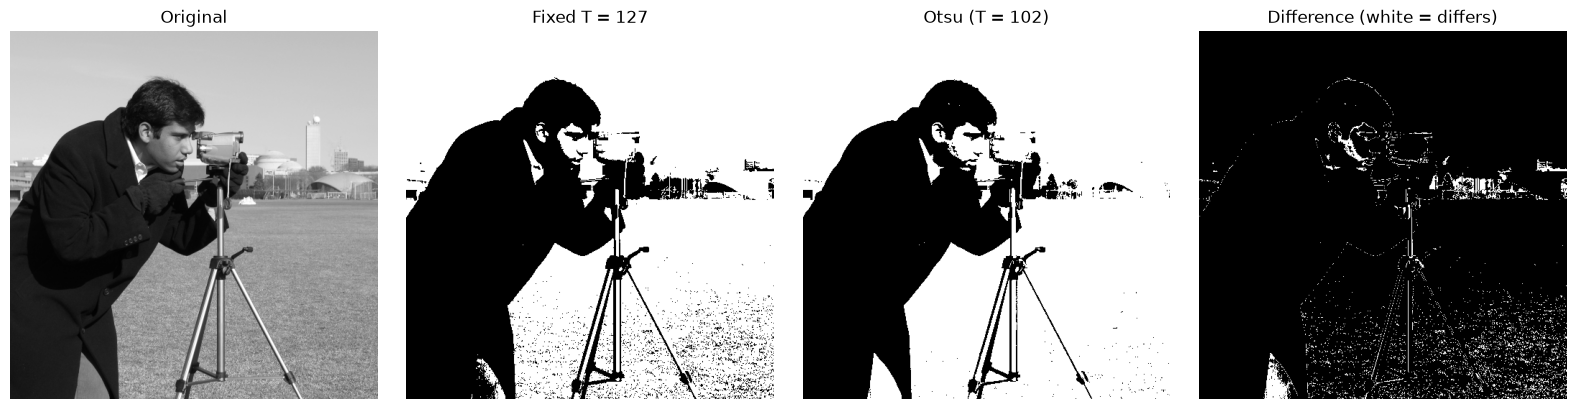

In [22]:
otsu_T, otsu = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold returned:", otsu_T)

diff = cv2.absdiff(fixed, otsu)
print(f"Pixels where fixed (127) and Otsu masks differ: {(diff > 0).sum()} "
      f"({100 * (diff > 0).mean():.2f}%)")
print(f"White pixels: fixed={(fixed == 255).sum()}, Otsu={(otsu == 255).sum()}")

show_images([original, fixed, otsu, diff],
            ["Original", "Fixed T = 127", f"Otsu (T = {otsu_T:.0f})", "Difference (white = differs)"], cols=4)

## 11. Adaptive Gaussian thresholding  (blockSize = 11, C = 2)
### Dry run

In [23]:
nb = np.array([[100, 100, 100],
               [100, 120, 140],
               [140, 140, 140]], dtype=np.float64)
wts = np.array([[1, 2, 1],
                [2, 4, 2],
                [1, 2, 1]], dtype=np.float64) / 16

weighted_mean = (nb * wts).sum()
T_local = weighted_mean - 2
center = nb[1, 1]
print("Weighted sum of products:", (nb * wts).sum())
print("Weighted mean:", weighted_mean, "| T = mean - 2 =", T_local)
print(f"Center pixel {center:.0f} > {T_local:.0f}? {center > T_local} -> output {255 if center > T_local else 0}")
equal_px = T_local
print(f"Pixel equal to T ({equal_px:.0f}) > T? {equal_px > T_local} -> output {255 if equal_px > T_local else 0}")
assert weighted_mean == 120 and T_local == 118
assert center > T_local and not (equal_px > T_local)

Weighted sum of products: 120.0
Weighted mean: 120.0 | T = mean - 2 = 118.0
Center pixel 120 > 118? True -> output 255
Pixel equal to T (118) > T? False -> output 0


The centre pixel (120) is greater than T = 118, so it becomes 255. A pixel exactly equal to T fails the strict `r > T` test and becomes 0.

Unique values: [0, 255]


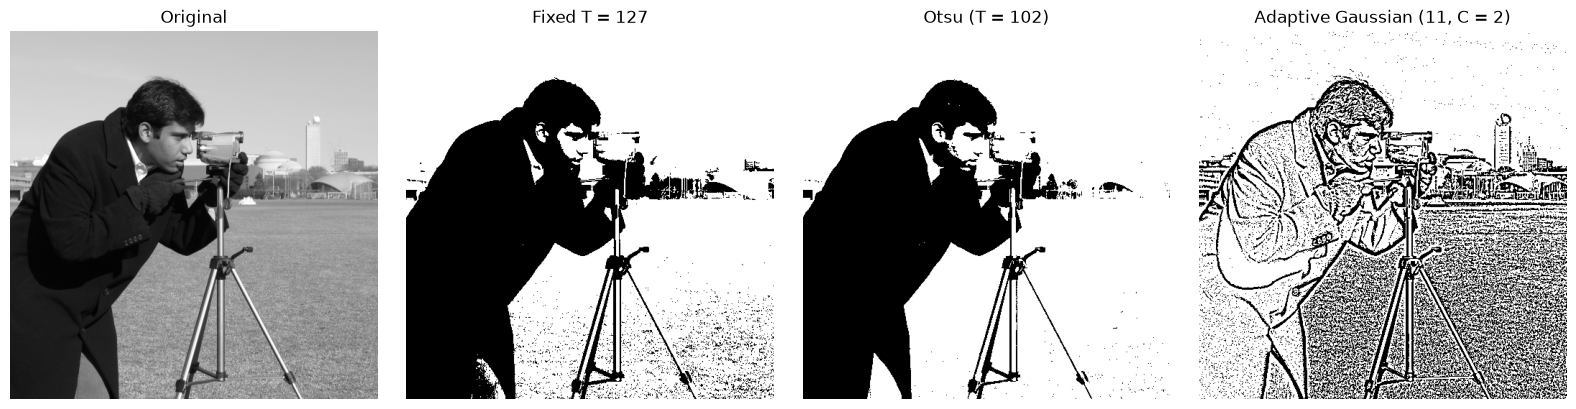

White pixels: fixed=168559, Otsu=177984, adaptive=191768


In [24]:
adaptive = cv2.adaptiveThreshold(original, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
print("Unique values:", np.unique(adaptive).tolist())
show_images([original, fixed, otsu, adaptive],
            ["Original", "Fixed T = 127", f"Otsu (T = {otsu_T:.0f})", "Adaptive Gaussian (11, C = 2)"], cols=4)
print(f"White pixels: fixed={(fixed == 255).sum()}, Otsu={(otsu == 255).sum()}, adaptive={(adaptive == 255).sum()}")

**Comparison:** fixed and Otsu thresholds use one global value, so under uneven lighting or shadows large regions turn entirely black or white. Adaptive thresholding computes a threshold from each pixel's 11 × 11 Gaussian-weighted neighbourhood, so it keeps local structure (text, edges, textures) despite lighting changes. The trade-off is that flat regions become noisy, because tiny local differences are compared with mean − C.